In [34]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence \
    import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm
import ISLP
from ISLP.models import ModelSpec, summarize, poly
from matplotlib import pyplot as plt
import seaborn as sns
from sympy.polys.dispersion import dispersionset

we use the `ILSP.load_data()` to import a dataset `Boston` from the package. at first we focus on lstat as feature and medv as the label

In [35]:
Boston = ISLP.load_data('Boston')
Boston[['lstat', 'medv']].head()

,lstat,medv
0,4.98,24.0
1,9.14,21.6
2,4.03,34.7
3,2.94,33.4
4,5.33,36.2


we can use `pd.DataFrame()` to make a new table named `X` to split feature from label. but we can also use `ModelSpec()` from `ISLP.models` to create scalable matrix from the data. we then can `fit()` the Model to a variable, use `transform()` onto our data with that variable onto our new table, or directly `fit_transform()` the `ModelSpec` to our Data - `Boston` - and assign it to our variable - `X`.

In [36]:
# X = pd.DataFrame({'intercept': np.ones(len(Boston)), 'lstat': Boston['lstat']})
design = ModelSpec(['lstat'])
X = design.fit_transform(Boston)
y = Boston['medv']
X.head()

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94
4,1.0,5.33


sm.OLS stands for: `statsmodels.api.OLS` = `Ordinary Least Squares`. It’s the function to create a `linear regression` model in `statsmodels`. refer to the below table to see difference with sklearn. we can see a summarization of the data using `summarize()` or `model.summary()` or `model.params`

| feature|statsmodels|sklearn|
|---|---|---|
|goal|statistics|machine learning|
|output|summary of values|just coeff and predictions|
|intercept|needs to be added|is added automatically|
|fit method| model = sm.OLS(y,X); model.fit()| model = LinearRegression(); model.fit(X,y)|

In [37]:
model = sm.OLS(y, X).fit()
display(model.rsquared, summarize(model))

np.float64(0.5441462975864799)

,coef,std err,t,P>|t|
intercept,34.5538,0.563,61.415,0.0
lstat,-0.9500,0.039,-24.528,0.0


In [38]:
model.conf_int(alpha=0.05)

,0,1
intercept,33.448457,35.659225
lstat,-1.026148,-0.873951


In [39]:
new_df = pd.DataFrame({'lstat':[2, 5, 10, 15, 22, 30]})
newX = design.transform(new_df)
newX

,intercept,lstat
0,1.0,2
1,1.0,5
2,1.0,10
3,1.0,15
4,1.0,22
5,1.0,30


In [52]:
y_pred = model.get_prediction(newX)
y_pred.predicted_mean

array([32.65374217, 29.80359411, 25.05334734, 20.30310057, 13.6527551 ,
        6.05236027])

In [41]:
y_pred.conf_int(alpha=0.05)

array([[31.67806791, 33.62941644],
       [29.00741194, 30.59977628],
       [24.47413202, 25.63256267],
       [19.73158815, 20.87461299],
       [12.7579569 , 14.54755329],
       [ 4.62500435,  7.47971618]])

In [42]:
y_pred.conf_int(obs=True, alpha=0.05)

array([[20.40283593, 44.90464841],
       [17.56567478, 42.04151344],
       [12.82762635, 37.27906833],
       [ 8.0777421 , 32.52845905],
       [ 1.40802451, 25.89748569],
       [-6.24276512, 18.34748566]])

 For instance, the 95% confidence interval associated with an
 `lstat`  value of 10 is (24.47, 25.63), and the 95% prediction
interval is (12.82, 37.28).  As expected, the confidence and
prediction intervals are centered around the same point (a predicted
value of 25.05 for  `medv`  when  `lstat`  equals
10), but the latter are substantially wider.

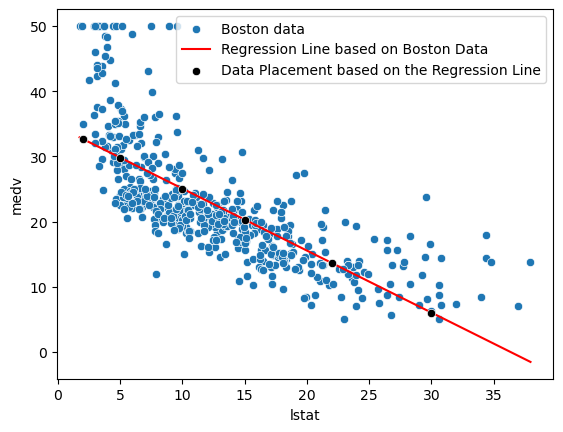

In [59]:
sns.scatterplot(
    x=Boston['lstat'], y=Boston['medv'], label='Boston data'
)
sns.lineplot(
    x=X['lstat'], y=model.predict(X), label='Regression Line based on Boston Data', color='red'
    )

sns.scatterplot(
    x=new_df['lstat'], y=y_pred.predicted_mean, color='black', label='Data Placement based on the Regression Line', zorder=2
);

There is some evidence for non-linearity in the relationship between  `lstat`  and  `medv`. We will explore this issue later in this lab.
Next we examine some diagnostic plots, several of which were discussed
in Section 3.3.3.
We can find the fitted values and residuals
of the fit as attributes of the `model` object.

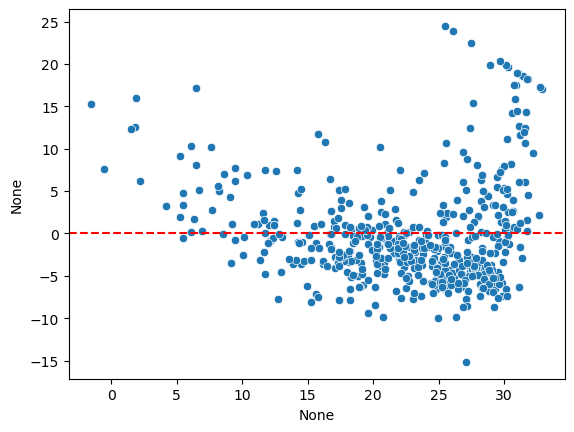

In [53]:
sns.scatterplot(x=model.fittedvalues, y=model.resid)
plt.axhline(y=0, linestyle='--', color='red');

We add a horizontal line at 0 for reference using the
 `ax.axhline()`   method. On the basis of the residual plot, there is some evidence of non-linearity.

## Multiple Linear Regression
In order to fit a multiple linear regression model using `least squares`, we again use
the `ModelSpec()`  transform to construct the required
model matrix and response. The arguments
to `ModelSpec()` can be quite general, but in this case
a list of column names suffice. We consider a fit here with
the two variables `lstat` and `age`.

In [57]:
cols = ['lstat', 'age']
X1 = ModelSpec(cols).fit_transform(Boston)
model1 = sm.OLS(y, X1).fit()
display(model1.rsquared, summarize(model1))

np.float64(0.5512689379421002)

,coef,std err,t,P>|t|
intercept,33.2228,0.731,45.458,0.000
lstat,-1.0321,0.048,-21.416,0.000
age,0.0345,0.012,2.826,0.005


Notice how we have compacted the first line into a succinct expression describing the construction of `X`.

The  `Boston`   data set contains 12 variables, and so it would be cumbersome
to have to type all of these in order to perform a regression using all of the predictors.
Instead, we can use the following

We can now fit the model with all the variables in `predictors` using
the same model matrix builder.

In [ ]:
predictors = Boston.columns.drop('medv')
X2 = ModelSpec(predictors).fit_transform(Boston)
model2 = sm.OLS(y, X2).fit()
# result1 = model2.get_prediction
display(model2.rsquared, summarize(model2))

np.float64(0.7343070437613075)

,coef,std err,t,P>|t|
intercept,41.6173,4.936,8.431,0.000
crim,-0.1214,0.033,-3.678,0.000
zn,0.0470,0.014,3.384,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8400,0.870,3.264,0.001
nox,-18.7580,3.851,-4.870,0.000
rm,3.6581,0.420,8.705,0.000
age,0.0036,0.013,0.271,0.787
dis,-1.4908,0.202,-7.394,0.000
rad,0.2894,0.067,4.325,0.000


as we can see the rsquared value of the regression line went up from 54 to 55 to 73 by just including more faetures.